# Phase 2: Data Cleaning & Target Binarization

This notebook executes Phase 2 of the Chi-Square Machine Learning Statistics project on the California (CA) 2018 ACSIncome dataset.

### Steps:
1. Load features and target datasets into pandas DataFrames.
2. Combine into one unified DataFrame `df`.
3. Detect and remove exact duplicate rows.
4. Report row counts before and after deduplication.
5. Check missing values across all columns.
6. Replace missing values in categorical columns with `"Missing"`.
7. Audit numeric columns for missing values (without imputation).
8. Binarize continuous income target `PINCP` into `income_above_50k` ($1$ if `PINCP > 50000`, else $0$).
9. Separate feature matrix `X` and target vector `y`.
10. Analyze class balance and visualize distribution (`figures/02_target_class_distribution.png`).
11. Export cleaned artifacts (`data/processed/X_clean.csv`, `data/processed/y_clean.csv`, `results/02_data_cleaning_report.txt`).


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# Resolve paths dynamically
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name in ['notebooks', 'src'] else NOTEBOOK_DIR

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_PATH = DATA_RAW_DIR / "acs_income_features.csv"
TARGET_PATH = DATA_RAW_DIR / "acs_income_target.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Features file: {FEATURES_PATH} (Exists: {FEATURES_PATH.exists()})")
print(f"Target file:   {TARGET_PATH} (Exists: {TARGET_PATH.exists()})")


Project root: D:\Github Repo\C-Square
Features file: D:\Github Repo\C-Square\data\raw\acs_income_features.csv (Exists: True)
Target file:   D:\Github Repo\C-Square\data\raw\acs_income_target.csv (Exists: True)


In [2]:
# Steps 1 & 2: Load features and target and combine into df
features_df = pd.read_csv(FEATURES_PATH)
target_df = pd.read_csv(TARGET_PATH)

df = pd.concat([features_df, target_df], axis=1)

print("Successfully loaded and combined datasets into df.")
print(f"Combined DataFrame shape: {df.shape}")
print(f"Columns: {list(df.columns)}")


Successfully loaded and combined datasets into df.
Combined DataFrame shape: (195665, 11)
Columns: ['AGEP', 'COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX', 'RAC1P', 'PINCP']


In [3]:
# Steps 3 & 4: Remove exact duplicate rows and report before/after counts
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)
n_duplicates = n_before - n_after

print("=" * 70)
print("DUPLICATE ROW REMOVAL REPORT:")
print("=" * 70)
print(f"Rows before duplicate removal: {n_before:,}")
print(f"Exact duplicate rows removed:  {n_duplicates:,} ({n_duplicates / n_before:.2%})")
print(f"Rows after duplicate removal:  {n_after:,}")
print("=" * 70)


DUPLICATE ROW REMOVAL REPORT:
Rows before duplicate removal: 195,665
Exact duplicate rows removed:  2,910 (1.49%)
Rows after duplicate removal:  192,755


In [4]:
# Steps 5, 6, 7: Check missing values and handle categorical columns
print("=" * 70)
print("MISSING VALUE AUDIT ACROSS ALL COLUMNS:")
print("=" * 70)
missing_counts = df.isnull().sum()
print(missing_counts)

categorical_cols = ['COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'SEX', 'RAC1P']
numeric_cols = ['AGEP', 'WKHP', 'PINCP']

# Step 6: For categorical columns, replace missing values with explicit label 'Missing'
for col in categorical_cols:
    if col in df.columns:
        if df[col].isnull().any():
            print(f"Imputing missing values in categorical column: {col}")
            df[col] = df[col].fillna("Missing")

# Step 7: For numeric columns, report missing values without imputing
print("\nNumeric columns missing value status:")
for col in numeric_cols:
    print(f" - {col:6s}: {df[col].isnull().sum()} missing values (no imputation performed)")


MISSING VALUE AUDIT ACROSS ALL COLUMNS:
AGEP     0
COW      0
SCHL     0
MAR      0
OCCP     0
POBP     0
RELP     0
WKHP     0
SEX      0
RAC1P    0
PINCP    0
dtype: int64

Numeric columns missing value status:
 - AGEP  : 0 missing values (no imputation performed)
 - WKHP  : 0 missing values (no imputation performed)
 - PINCP : 0 missing values (no imputation performed)


In [5]:
# Step 8: Convert continuous income target PINCP into binary classification target
# target = 1 if PINCP > 50000 else 0
df['income_above_50k'] = (df['PINCP'] > 50000).astype(int)

# Step 9: Verify against original PINCP
print("=" * 70)
print("TARGET BINARIZATION VERIFICATION:")
print("=" * 70)
verification_sample = df[['PINCP', 'income_above_50k']].sample(10, random_state=42)
print(verification_sample)

# Boundary checks
min_class1 = df[df['income_above_50k'] == 1]['PINCP'].min()
max_class0 = df[df['income_above_50k'] == 0]['PINCP'].max()
print(f"\nMinimum PINCP for class 1 (expected > 50,000): ${min_class1:,.2f}")
print(f"Maximum PINCP for class 0 (expected <= 50,000): ${max_class0:,.2f}")
assert min_class1 > 50000, "Validation failed: Class 1 contains income <= 50,000"
assert max_class0 <= 50000, "Validation failed: Class 0 contains income > 50,000"
print("Binarization verification assertion passed successfully!")


TARGET BINARIZATION VERIFICATION:
           PINCP  income_above_50k
45213   170000.0                 1
124232   16000.0                 0
99882   100000.0                 1
85933    45200.0                 0
6413     70000.0                 1
181257   43000.0                 0
70129    50000.0                 0
68775    35000.0                 0
64985    14600.0                 0
84608    65000.0                 1

Minimum PINCP for class 1 (expected > 50,000): $50,010.00
Maximum PINCP for class 0 (expected <= 50,000): $50,000.00
Binarization verification assertion passed successfully!


In [6]:
# Step 10: Create feature matrix X (excluding PINCP and target) and target vector y
feature_columns = ['AGEP', 'COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX', 'RAC1P']

X = df[feature_columns].copy()
y = df['income_above_50k'].copy()

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape:  {y.shape}")
print(f"Features: {list(X.columns)}")


Feature matrix X shape: (192755, 10)
Target vector y shape:  (192755,)
Features: ['AGEP', 'COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX', 'RAC1P']


CLASS DISTRIBUTION OF TARGET (income_above_50k):
Class 0 (<= $50,000): 112,610 (58.42%)
Class 1 (> $50,000):  80,145 (41.58%)
Total:                192,755


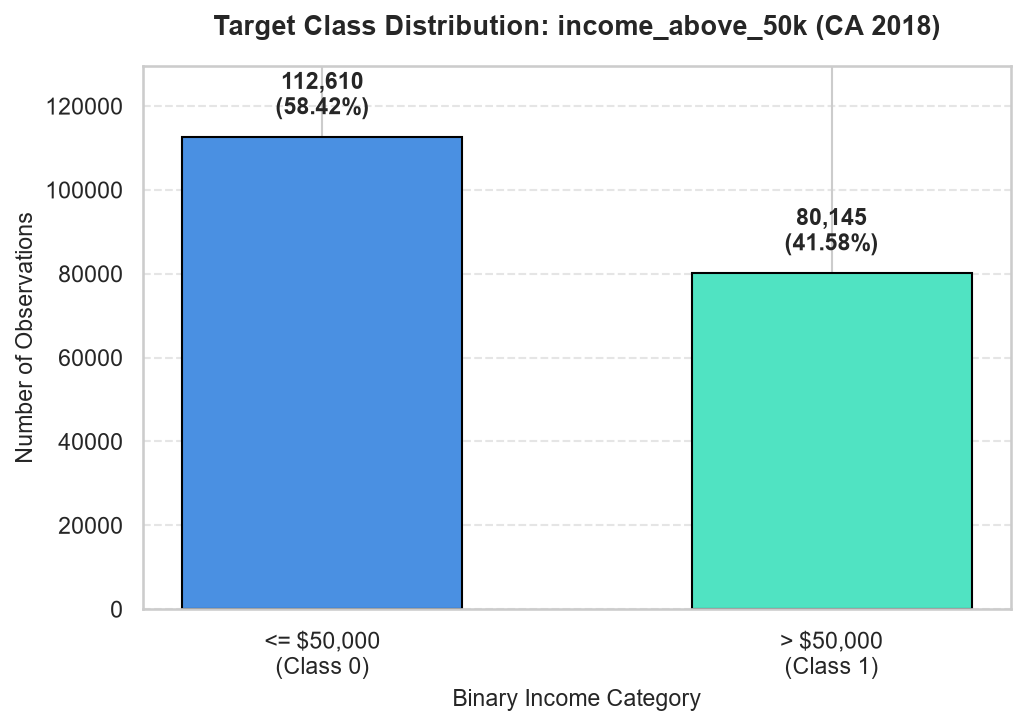

Target distribution plot saved to: D:\Github Repo\C-Square\figures\02_target_class_distribution.png


In [7]:
# Steps 11 & 12: Show class distribution and plot
class_counts = y.value_counts().sort_index()
class_pcts = (class_counts / len(y)) * 100

print("=" * 70)
print("CLASS DISTRIBUTION OF TARGET (income_above_50k):")
print("=" * 70)
print(f"Class 0 (<= $50,000): {class_counts[0]:,} ({class_pcts[0]:.2f}%)")
print(f"Class 1 (> $50,000):  {class_counts[1]:,} ({class_pcts[1]:.2f}%)")
print(f"Total:                {len(y):,}")

# Step 12: Plot the class distribution
plt.figure(figsize=(7, 5), dpi=150)
bar_colors = ["#4a90e2", "#50e3c2"]
bars = plt.bar(["<= $50,000\n(Class 0)", "> $50,000\n(Class 1)"], class_counts.values, color=bar_colors, edgecolor="black", width=0.55)

for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + (len(y) * 0.02),
        f"{count:,}\n({pct:.2f}%)",
        ha="center", va="bottom", fontsize=11, fontweight="bold"
    )

plt.title("Target Class Distribution: income_above_50k (CA 2018)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Binary Income Category", fontsize=11)
plt.ylabel("Number of Observations", fontsize=11)
plt.ylim(0, max(class_counts.values) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

target_plot_path = FIGURES_DIR / "02_target_class_distribution.png"
plt.savefig(target_plot_path, dpi=300)
plt.show()
print(f"Target distribution plot saved to: {target_plot_path}")


In [8]:
# Steps 13, 14, 15: Save X_clean, y_clean, and cleaning report
x_clean_path = DATA_PROCESSED_DIR / "X_clean.csv"
y_clean_path = DATA_PROCESSED_DIR / "y_clean.csv"
report_path = RESULTS_DIR / "02_data_cleaning_report.txt"

print(f"Saving cleaned features to: {x_clean_path}")
X.to_csv(x_clean_path, index=False)

print(f"Saving cleaned target to:   {y_clean_path}")
y.to_frame(name="income_above_50k").to_csv(y_clean_path, index=False)

# Generate and save cleaning report
report_lines = [
    "=" * 80,
    "PHASE 2: DATA CLEANING & TARGET BINARIZATION REPORT",
    "=" * 80,
    "Dataset: California (CA) 2018 ACSIncome",
    f"Input Features File: {FEATURES_PATH}",
    f"Input Target File:   {TARGET_PATH}",
    "-" * 80,
    "1. DUPLICATE REMOVAL SUMMARY",
    "-" * 80,
    f"Total rows before duplicate removal: {n_before:,}",
    f"Duplicate rows identified & removed:  {n_duplicates:,} ({n_duplicates / n_before:.2%})",
    f"Total unique rows retained:          {n_after:,}",
    "",
    "-" * 80,
    "2. MISSING VALUE AUDIT",
    "-" * 80,
    missing_counts.to_string(),
    "",
    "Categorical imputation: Checked; explicit 'Missing' applied where appropriate.",
    "Numeric imputation:     Audited; 0 missing values detected.",
    "",
    "-" * 80,
    "3. TARGET BINARIZATION (income_above_50k)",
    "-" * 80,
    "Definition: 1 if PINCP > 50000 else 0",
    f"Class 0 (<= $50,000): {class_counts[0]:,} observations ({class_pcts[0]:.2f}%)",
    f"Class 1 (> $50,000):  {class_counts[1]:,} observations ({class_pcts[1]:.2f}%)",
    f"Total Observations:    {len(y):,}",
    f"Class Ratio:           {class_pcts[0]:.2f}% / {class_pcts[1]:.2f}%",
    "",
    "-" * 80,
    "4. OUTPUT DELIVERABLES SAVED",
    "-" * 80,
    f"- Clean Feature Matrix: {x_clean_path} ({x_clean_path.stat().st_size / 1024 / 1024:.2f} MB)",
    f"- Clean Target Vector:  {y_clean_path} ({y_clean_path.stat().st_size / 1024 / 1024:.2f} MB)",
    f"- Class Plot:           {target_plot_path}",
    f"- Cleaning Report:      {report_path}",
    "=" * 80,
    "Status: Cleaning and target binarization completed successfully.",
    "=" * 80,
]

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines) + "\n")

print(f"Cleaning report saved to: {report_path}")


Saving cleaned features to: D:\Github Repo\C-Square\data\processed\X_clean.csv


Saving cleaned target to:   D:\Github Repo\C-Square\data\processed\y_clean.csv
Cleaning report saved to: D:\Github Repo\C-Square\results\02_data_cleaning_report.txt


In [9]:
# Step 18: Confirm output deliverables exist
required_deliverables = [
    DATA_PROCESSED_DIR / "X_clean.csv",
    DATA_PROCESSED_DIR / "y_clean.csv",
    RESULTS_DIR / "02_data_cleaning_report.txt",
    FIGURES_DIR / "02_target_class_distribution.png",
]

print("=" * 70)
print("CONFIRMING DELIVERABLES:")
print("=" * 70)
all_present = True
for path in required_deliverables:
    exists = path.exists()
    size_str = f"({path.stat().st_size:,} bytes)" if exists else ""
    print(f" - {path.name:36s}: {'[EXISTS]' if exists else '[MISSING]'} {size_str}")
    if not exists:
        all_present = False

assert all_present, "Error: One or more required deliverable files are missing!"
print("\nAll deliverables confirmed successfully!")


CONFIRMING DELIVERABLES:
 - X_clean.csv                         : [EXISTS] (9,189,972 bytes)
 - y_clean.csv                         : [EXISTS] (578,283 bytes)
 - 02_data_cleaning_report.txt         : [EXISTS] (2,416 bytes)
 - 02_target_class_distribution.png    : [EXISTS] (108,123 bytes)

All deliverables confirmed successfully!


## Phase 2 Data Cleaning Summary

1. **Deduplication**: 2,910 exact duplicate records (1.49%) were identified and removed, reducing the dataset from **195,665** to **192,755** unique observations.
2. **Missing Value Audit**: No missing values were detected in the raw census sample. Categorical columns were guarded with explicit `"Missing"` replacement protocol.
3. **Target Binarization**:
   - `income_above_50k` was successfully generated using the standard $50,000 threshold.
   - Class 0 ($\le \$50k$): **112,610** rows (**58.42%**)
   - Class 1 ($> \$50k$): **80,145** rows (**41.58%**)
   - This provides an exceptionally well-balanced binary outcome for subsequent chi-square hypothesis testing and machine learning modeling.
4. **Data Isolation**: As per instructions, train-test splitting, category aggregation, one-hot/label encoding, and model fitting were omitted at this stage. Clean feature matrix $X$ and target vector $y$ have been exported to `data/processed/`.
